**PREPROCESSING**

In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/spotify_data.csv")

df.head()

,user_id,artistname,trackname,playlistname,song_id,danceability,energy,key,loudness,mode,...,instrumentalness,liveness,valence,tempo,type,duration_ms,time_signature,analysis_url,uri,id
0,c1a6910ecac9fd5e5348326675fb6ca6,Jon Hopkins,Abandon Window,CHILL,5BKp7nLEzAtazOxYla2sBr,0.063,0.1730,6.0,-26.199,1.0,...,0.836000,0.0863,0.1120,68.963,audio_features,297493.0,3.0,https://api.spotify.com/v1/audio-analysis/5BKp...,spotify:track:5BKp7nLEzAtazOxYla2sBr,5BKp7nLEzAtazOxYla2sBr
1,c1a6910ecac9fd5e5348326675fb6ca6,Grouper,Clearing,CHILL,3IL43TRkEnh4buGOZ1Brb5,0.230,0.0432,6.0,-23.066,1.0,...,0.932000,0.1050,0.1360,89.582,audio_features,281680.0,4.0,https://api.spotify.com/v1/audio-analysis/3IL4...,spotify:track:3IL43TRkEnh4buGOZ1Brb5,3IL43TRkEnh4buGOZ1Brb5
2,c1a6910ecac9fd5e5348326675fb6ca6,Com Truise,Closed,CHILL,1z2iz13gYpqnH4IwUQsSLx,0.623,0.5200,2.0,-7.926,1.0,...,0.839000,0.0899,0.1720,172.051,audio_features,184000.0,4.0,https://api.spotify.com/v1/audio-analysis/1z2i...,spotify:track:1z2iz13gYpqnH4IwUQsSLx,1z2iz13gYpqnH4IwUQsSLx
3,c1a6910ecac9fd5e5348326675fb6ca6,Radiohead,Codex,CHILL,6ttYF5VadzTssGV2i1Q08T,0.346,0.1280,2.0,-17.536,0.0,...,0.760000,0.1300,0.0654,58.996,audio_features,287067.0,4.0,https://api.spotify.com/v1/audio-analysis/6ttY...,spotify:track:6ttYF5VadzTssGV2i1Q08T,6ttYF5VadzTssGV2i1Q08T
4,c1a6910ecac9fd5e5348326675fb6ca6,Nina Simone,Cotton Eyed Joe,CHILL,3d5Mw0esNjnh123xyy48IF,0.421,0.0820,0.0,-18.893,1.0,...,0.000209,0.1280,0.2040,72.529,audio_features,171280.0,4.0,https://api.spotify.com/v1/audio-analysis/3d5M...,spotify:track:3d5Mw0esNjnh123xyy48IF,3d5Mw0esNjnh123xyy48IF


In [ ]:
print("Shape of dataset:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape of dataset: (28469, 22)

Columns:
['user_id', 'artistname', 'trackname', 'playlistname', 'song_id', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'type', 'duration_ms', 'time_signature', 'analysis_url', 'uri', 'id']

Data types:
user_id              object
artistname           object
trackname            object
playlistname         object
song_id              object
danceability        float64
energy              float64
key                 float64
loudness            float64
mode                float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
type                 object
duration_ms         float64
time_signature      float64
analysis_url         object
uri                  object
id                   object
dtype: object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28469 entries, 0 to 28468
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           28469 non-null  object 
 1   artistname        28469 non-null  object 
 2   trackname         28469 non-null  object 
 3   playlistname      28469 non-null  object 
 4   song_id           28469 non-null  object 
 5   danceability      28469 non-null  float64
 6   energy            28469 non-null  float64
 7   key               28469 non-null  float64
 8   loudness          28469 non-null  float64
 9   mode              28469 non-null  float64
 10  speechiness       28469 non-null  float64
 11  acousticness      28469 non-null  float64
 12  instrumentalness  28469 non-null  float64
 13  liveness          28469 non-null  float64
 14  valence           28469 non-null  float64
 15  tempo             28469 non-null  float64
 16  type              28469 non-null  object

In [ ]:
missing = df.isnull().sum()

print(missing[missing > 0])

Series([], dtype: int64)


In [ ]:
print("Before removing duplicate shape:",df.shape)
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Before removing duplicate shape: (28469, 22)
Duplicate rows: 0
Shape after removing duplicates: (28469, 22)


In [ ]:
text_columns = [
    'artistname',
    'trackname',
    'playlistname'
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

In [ ]:
numeric_columns = [
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'duration_ms',
    'time_signature'
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
columns_to_drop = [
    'analysis_url',
    'uri',
    'type'
]

df = df.drop(columns=columns_to_drop)

print(df.columns.tolist())
print(df.shape)

['user_id', 'artistname', 'trackname', 'playlistname', 'song_id', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature', 'id']
(28469, 19)


In [ ]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

X = df[features]

print("Features selected:")
print(features)

print("\nShape:", X.shape)

Features selected:
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

Shape: (28469, 9)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (28469, 9)


In [ ]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df.index
)

X_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,-2.810016,-1.891527,-3.666158,-0.237237,1.678886,2.328850,-0.645181,-1.449511,-1.841485
1,-1.840194,-2.415083,-3.019307,-0.349386,2.262553,2.654825,-0.541681,-1.355200,-1.122441
2,0.442082,-0.491882,0.106559,-0.210729,-0.815649,2.339037,-0.625256,-1.213734,1.753493
3,-1.166545,-2.073037,-1.877560,-0.468671,1.794371,2.070787,-0.403312,-1.632632,-2.189063
4,-0.730996,-2.258581,-2.157732,-0.327976,2.153310,-0.509136,-0.414382,-1.087986,-1.717128


In [ ]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nScaled feature data:")
print(X_scaled.head())

Final dataset shape: (28469, 19)

Missing values:
0

Duplicate rows:
0

Scaled feature data:
   danceability    energy  loudness  speechiness  acousticness  \
0     -2.810016 -1.891527 -3.666158    -0.237237      1.678886   
1     -1.840194 -2.415083 -3.019307    -0.349386      2.262553   
2      0.442082 -0.491882  0.106559    -0.210729     -0.815649   
3     -1.166545 -2.073037 -1.877560    -0.468671      1.794371   
4     -0.730996 -2.258581 -2.157732    -0.327976      2.153310   

   instrumentalness  liveness   valence     tempo  
0          2.328850 -0.645181 -1.449511 -1.841485  
1          2.654825 -0.541681 -1.355200 -1.122441  
2          2.339037 -0.625256 -1.213734  1.753493  
3          2.070787 -0.403312 -1.632632 -2.189063  
4         -0.509136 -0.414382 -1.087986 -1.717128  


**EDA**

playlistname
Starred                  1391
Liked from Radio          460
2012                      412
Favoritas de la radio     412
My Shazam Tracks          148
01                        138
Christmas                 126
Deluxe                    122
Disney                    122
2014's Best               121
Name: count, dtype: int64


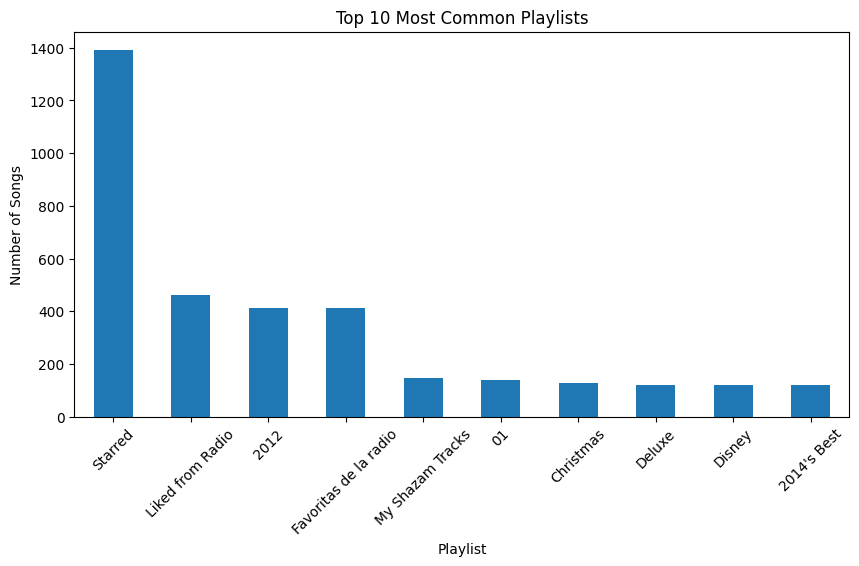

In [ ]:
import matplotlib.pyplot as plt
playlist_counts = df['playlistname'].value_counts().head(10)

print(playlist_counts)

plt.figure(figsize=(10, 5))
playlist_counts.plot(kind='bar')
plt.title("Top 10 Most Common Playlists")
plt.xlabel("Playlist")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45)
plt.show()

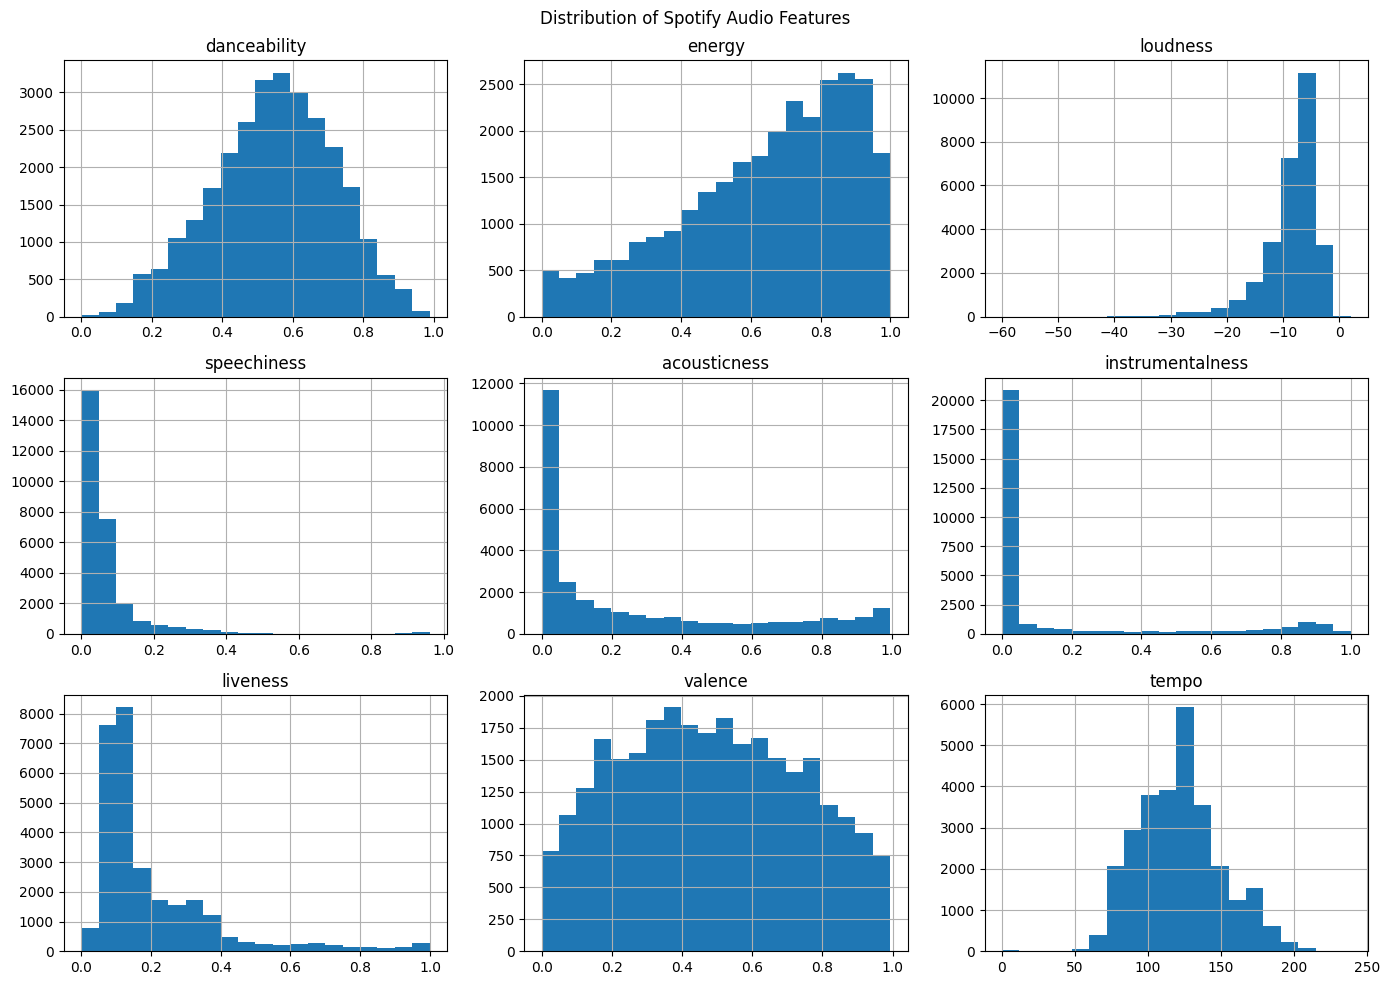

In [ ]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[features].hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Spotify Audio Features")
plt.tight_layout()
plt.show()

In [ ]:
user_counts = df['user_id'].value_counts()

print("Number of users:", df['user_id'].nunique())
print("\nSongs per user:")
print(user_counts.describe())

Number of users: 250

Songs per user:
count    250.000000
mean     113.876000
std        3.769011
min      103.000000
25%      112.000000
50%      114.000000
75%      116.750000
max      122.000000
Name: count, dtype: float64


In [ ]:
print("Number of users:", df['user_id'].nunique())
print("Number of artists:", df['artistname'].nunique())
print("Number of tracks:", df['trackname'].nunique())
print("Number of playlists:", df['playlistname'].nunique())

Number of users: 250
Number of artists: 6185
Number of tracks: 21454
Number of playlists: 1078


**RECOMMENDATION** **SYSTEM**

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

song_features = df[features]

print("Song feature matrix shape:", song_features.shape)

Song feature matrix shape: (28469, 9)


In [ ]:
similarity_matrix = cosine_similarity(X_scaled)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (28469, 28469)


In [ ]:
def recommend_songs(song_name, n=5):

    matches = df[
        df['trackname'].str.lower() == song_name.lower()
    ]

    if matches.empty:
        print("Song not found.")
        return

    song_index = matches.index[0]

    similarity_scores = similarity_matrix[song_index]

    similar_indices = similarity_scores.argsort()[::-1]

    similar_indices = [
        i for i in similar_indices
        if i != song_index
    ]

    results = df.iloc[similar_indices[:n]].copy()

    results['similarity_score'] = [
        similarity_scores[i]
        for i in similar_indices[:n]
    ]

    return results[
        ['trackname', 'artistname',
         'playlistname', 'similarity_score']
    ]

In [ ]:
song = df['trackname'].dropna().iloc[0]

print("Selected song:", song)
print("Artist:", df.loc[df['trackname'] == song, 'artistname'].iloc[0])

Selected song: Abandon Window
Artist: Jon Hopkins


In [ ]:
recommend_songs(song, 5)

,trackname,artistname,playlistname,similarity_score
18283,Abandon Window,Jon Hopkins,113 Songs For 2013,1.000000
2296,Abandon Window,Jon Hopkins,Fina blandningen v2.0,1.000000
11874,"Mindful Yoga (Antigravity Music for Yoga, Gett...",The Yoga Specialists,My Shazam Tracks,0.994821
26321,Long Lankin,Various Artists,001 murder ballads,0.990868
1922,Anice Stellato,Gino Fioravanti,Starred,0.990773


In [ ]:
user_id = df['user_id'].iloc[0]

user_songs = df[df['user_id'] == user_id]

print("User:", user_id)
print("Number of songs:", len(user_songs))

user_songs[
    ['trackname', 'artistname', 'playlistname']
].head(10)

User: c1a6910ecac9fd5e5348326675fb6ca6
Number of songs: 112


,trackname,artistname,playlistname
0,Abandon Window,Jon Hopkins,CHILL
1,Clearing,Grouper,CHILL
2,Closed,Com Truise,CHILL
3,Codex,Radiohead,CHILL
4,Cotton Eyed Joe,Nina Simone,CHILL
5,Dust On The Ground,Bombay Bicycle Club,CHILL
6,Gagging Order,Radiohead,CHILL
7,Golden Arrow,Darkside,CHILL
8,Gymnopédie No. 1,Erik Satie,CHILL
9,Hello Stranger,Julia Holter,CHILL


In [ ]:
def recommend_for_user(user_id, n=10):

    # Songs listened to by the user
    user_data = df[df['user_id'] == user_id]

    if user_data.empty:
        print("User not found.")
        return pd.DataFrame(columns=[
            'trackname',
            'artistname',
            'playlistname',
            'recommendation_score'
        ])

    # Get indices of user's songs
    user_indices = user_data.index

    # Calculate average preference profile
    user_profile = X_scaled.loc[user_indices].mean(axis=0).values

    # Calculate similarity of every song to the user's profile
    scores = cosine_similarity(
        user_profile.reshape(1, -1),
        X_scaled.values
    )[0]

    # Add scores
    result = df.copy()
    result['recommendation_score'] = scores

    # Remove songs already listened to
    result = result[
        ~result.index.isin(user_indices)
    ]

    # Sort by similarity
    result = result.sort_values(
        'recommendation_score',
        ascending=False
    )

    return result[
        [
            'trackname',
            'artistname',
            'playlistname',
            'recommendation_score'
        ]
    ].head(n)


In [ ]:
# Generate recommendations for ALL users

TOP_N = 10
all_user_recommendations = []

all_users = df['user_id'].dropna().unique()

for i, current_user_id in enumerate(all_users, start=1):

    user_recommendations = recommend_for_user(
        current_user_id,
        n=TOP_N
    ).copy()

    if not user_recommendations.empty:
        user_recommendations.insert(0, 'user_id', current_user_id)
        user_recommendations['recommendation_rank'] = range(
            1, len(user_recommendations) + 1
        )
        all_user_recommendations.append(user_recommendations)

all_user_recommendations = pd.concat(
    all_user_recommendations,
    ignore_index=True
)

# Keep the original single-user variables so the remaining
# evaluation cells continue to work in the same format.
user_id = df['user_id'].iloc[0]
recommendations = recommend_for_user(
    user_id,
    n=TOP_N
)

print("Total users:", len(all_users))
print("Users with recommendations:",
      all_user_recommendations['user_id'].nunique())
print("Total recommendation rows:",
      len(all_user_recommendations))

all_user_recommendations.head(20)


Total users: 250
Users with recommendations: 250
Total recommendation rows: 2500


,user_id,trackname,artistname,playlistname,recommendation_score,recommendation_rank
0,c1a6910ecac9fd5e5348326675fb6ca6,Divenire,Ludovico Einaudi,Classical Music Bliss,0.979681,1
1,c1a6910ecac9fd5e5348326675fb6ca6,Divenire,Ludovico Einaudi,Random N,0.979681,2
2,c1a6910ecac9fd5e5348326675fb6ca6,Divenire,Ludovico Einaudi,DOWN,0.979681,3
3,c1a6910ecac9fd5e5348326675fb6ca6,Divenire,Ludovico Einaudi,"Clásica que sí, que gusta",0.979681,4
4,c1a6910ecac9fd5e5348326675fb6ca6,Mad World,Vitamin String Quartet,Covers,0.979645,5
5,c1a6910ecac9fd5e5348326675fb6ca6,Brand New Angel,Jeff Bridges,Crazy Heart: Original Motion Picture Soundtrack,0.979492,6
6,c1a6910ecac9fd5e5348326675fb6ca6,Les professionnels,Air,Air,0.976630,7
7,c1a6910ecac9fd5e5348326675fb6ca6,Slow Walker,Béla Fleck and the Flecktones,Bela Fleck,0.975587,8
8,c1a6910ecac9fd5e5348326675fb6ca6,New-York,Alexandra Streliski,Classical Music Bliss,0.974846,9
9,c1a6910ecac9fd5e5348326675fb6ca6,Once Upon A Time,Tugores,Everything,0.973840,10


In [ ]:
user_history = df[df['user_id'] == user_id]

print("User:", user_id)
print("\nPreviously listened songs:")

user_history[
    ['trackname', 'artistname', 'playlistname']
].head(10)

User: c1a6910ecac9fd5e5348326675fb6ca6

Previously listened songs:


,trackname,artistname,playlistname
0,Abandon Window,Jon Hopkins,CHILL
1,Clearing,Grouper,CHILL
2,Closed,Com Truise,CHILL
3,Codex,Radiohead,CHILL
4,Cotton Eyed Joe,Nina Simone,CHILL
5,Dust On The Ground,Bombay Bicycle Club,CHILL
6,Gagging Order,Radiohead,CHILL
7,Golden Arrow,Darkside,CHILL
8,Gymnopédie No. 1,Erik Satie,CHILL
9,Hello Stranger,Julia Holter,CHILL


In [ ]:
recommendations_clean = recommendations.drop_duplicates(
    subset=['trackname', 'artistname']
)

recommendations_clean

,trackname,artistname,playlistname,recommendation_score
28375,Divenire,Ludovico Einaudi,Classical Music Bliss,0.979681
22806,Mad World,Vitamin String Quartet,Covers,0.979645
3647,Brand New Angel,Jeff Bridges,Crazy Heart: Original Motion Picture Soundtrack,0.979492
27939,Les professionnels,Air,Air,0.976630
22378,Slow Walker,Béla Fleck and the Flecktones,Bela Fleck,0.975587
28452,New-York,Alexandra Streliski,Classical Music Bliss,0.974846
4111,Once Upon A Time,Tugores,Everything,0.973840


In [ ]:
top_5 = recommendations_clean.head(5)

top_5

,trackname,artistname,playlistname,recommendation_score
28375,Divenire,Ludovico Einaudi,Classical Music Bliss,0.979681
22806,Mad World,Vitamin String Quartet,Covers,0.979645
3647,Brand New Angel,Jeff Bridges,Crazy Heart: Original Motion Picture Soundtrack,0.979492
27939,Les professionnels,Air,Air,0.976630
22378,Slow Walker,Béla Fleck and the Flecktones,Bela Fleck,0.975587


**EVALUATION**

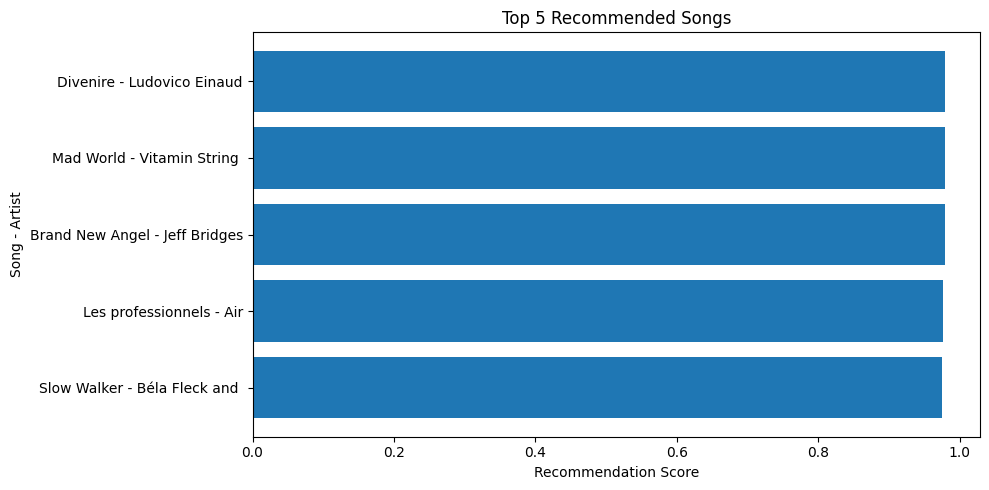

In [ ]:
import matplotlib.pyplot as plt

top_5_plot = top_5.copy()

labels = (
    top_5_plot['trackname'].astype(str).str[:20]
    + " - "
    + top_5_plot['artistname'].astype(str).str[:15]
)

plt.figure(figsize=(10, 5))

plt.barh(
    labels,
    top_5_plot['recommendation_score']
)

plt.xlabel("Recommendation Score")
plt.ylabel("Song - Artist")
plt.title("Top 5 Recommended Songs")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
print("Average recommendation score:",
      all_user_recommendations['recommendation_score'].mean())

print("Highest recommendation score:",
      all_user_recommendations['recommendation_score'].max())

print("Lowest recommendation score:",
      all_user_recommendations['recommendation_score'].min())

Average recommendation score: 0.9368881573129209
Highest recommendation score: 0.9991857390199014
Lowest recommendation score: 0.7137485865901367


In [ ]:
print("Average recommendation score:",
      top_5['recommendation_score'].mean())

print("Highest recommendation score:",
      top_5['recommendation_score'].max())

print("Lowest recommendation score:",
      top_5['recommendation_score'].min())

Average recommendation score: 0.9782070410063938
Highest recommendation score: 0.9796811091081574
Lowest recommendation score: 0.9755869687308774


In [ ]:
user_profile = X_scaled.loc[user_history.index].mean(axis=0)

print("User preference profile:")
print(user_profile)

User preference profile:
danceability        0.001763
energy             -0.254089
loudness           -0.231240
speechiness        -0.080320
acousticness        0.215877
instrumentalness    0.409601
liveness           -0.048055
valence            -0.115208
tempo              -0.153072
dtype: float64


In [ ]:
recommended_indices = recommendations_clean.head(10).index

recommended_features = X_scaled.loc[
    recommended_indices
]

user_similarity = cosine_similarity(
    user_profile.values.reshape(1, -1),
    recommended_features.values
)[0]

print(user_similarity)

[0.97968111 0.97964489 0.97949184 0.9766304  0.97558697 0.9748465
 0.97383965]


In [ ]:
average_similarity = user_similarity.mean()

print(
    "Average similarity of recommended songs:",
    round(average_similarity, 3)
)

Average similarity of recommended songs: 0.977


In [ ]:
# Final results for ALL users

final_results = all_user_recommendations[
    [
        'user_id',
        'recommendation_rank',
        'trackname',
        'artistname',
        'recommendation_score'
    ]
].copy()

final_results['recommendation_score'] = (
    final_results['recommendation_score'].round(3)
)

final_results

,user_id,recommendation_rank,trackname,artistname,recommendation_score
0,c1a6910ecac9fd5e5348326675fb6ca6,1,Divenire,Ludovico Einaudi,0.980
1,c1a6910ecac9fd5e5348326675fb6ca6,2,Divenire,Ludovico Einaudi,0.980
2,c1a6910ecac9fd5e5348326675fb6ca6,3,Divenire,Ludovico Einaudi,0.980
3,c1a6910ecac9fd5e5348326675fb6ca6,4,Divenire,Ludovico Einaudi,0.980
4,c1a6910ecac9fd5e5348326675fb6ca6,5,Mad World,Vitamin String Quartet,0.980
...,...,...,...,...,...
2495,f65b94ec7a3465012c0cf5b3cf64cbdf,6,"12 Grandes Etudes, S137/R2a: No. 3 in F Major:...",Franz Liszt,0.994
2496,f65b94ec7a3465012c0cf5b3cf64cbdf,7,Cäcilie,Richard Strauss,0.994
2497,f65b94ec7a3465012c0cf5b3cf64cbdf,8,Bolero of Fire,The St. Louis Ocarina Trio,0.993
2498,f65b94ec7a3465012c0cf5b3cf64cbdf,9,"Symphony No. 7 in A Major, Op. 92: III. Presto...",Ludwig van Beethoven,0.992


In [ ]:
final_results.to_csv(
    "spotify_recommendations.csv",
    index=False
)

print("Recommendations for ALL users saved successfully!")
print("Total recommendation rows:", len(final_results))


Recommendations for ALL users saved successfully!
Total recommendation rows: 2500


**GRAPHS**

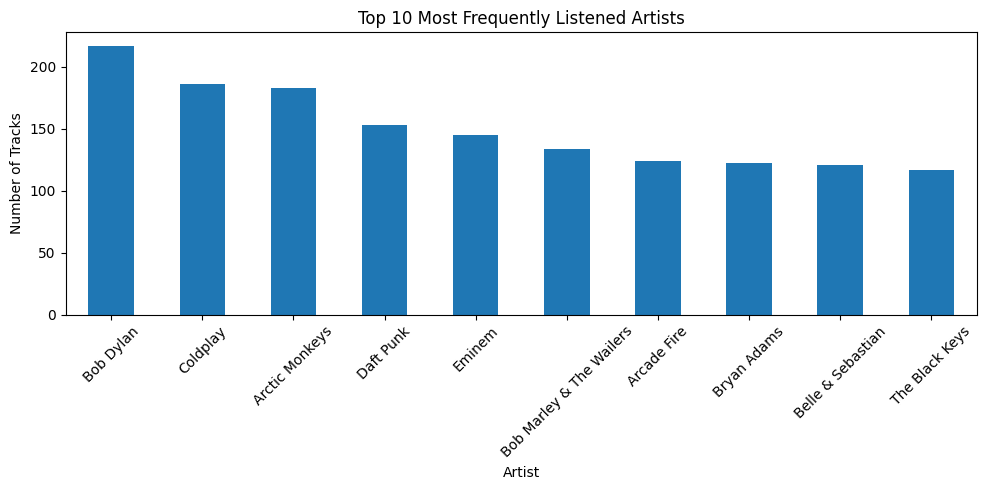

In [ ]:
import matplotlib.pyplot as plt

top_artists = df['artistname'].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_artists.plot(kind='bar')

plt.title("Top 10 Most Frequently Listened Artists")
plt.xlabel("Artist")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

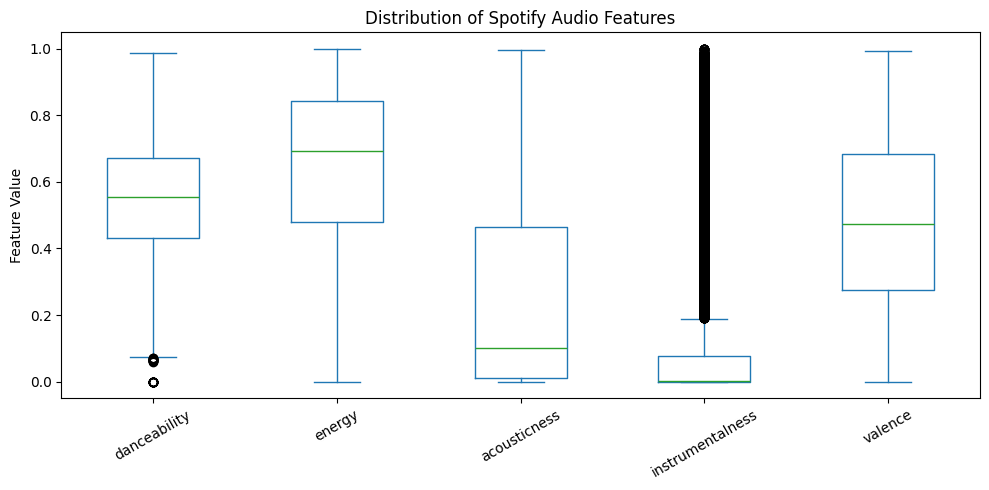

In [ ]:
audio_features = [
    'danceability',
    'energy',
    'acousticness',
    'instrumentalness',
    'valence'
]

df[audio_features].plot(
    kind='box',
    figsize=(10, 5)
)

plt.title("Distribution of Spotify Audio Features")
plt.ylabel("Feature Value")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

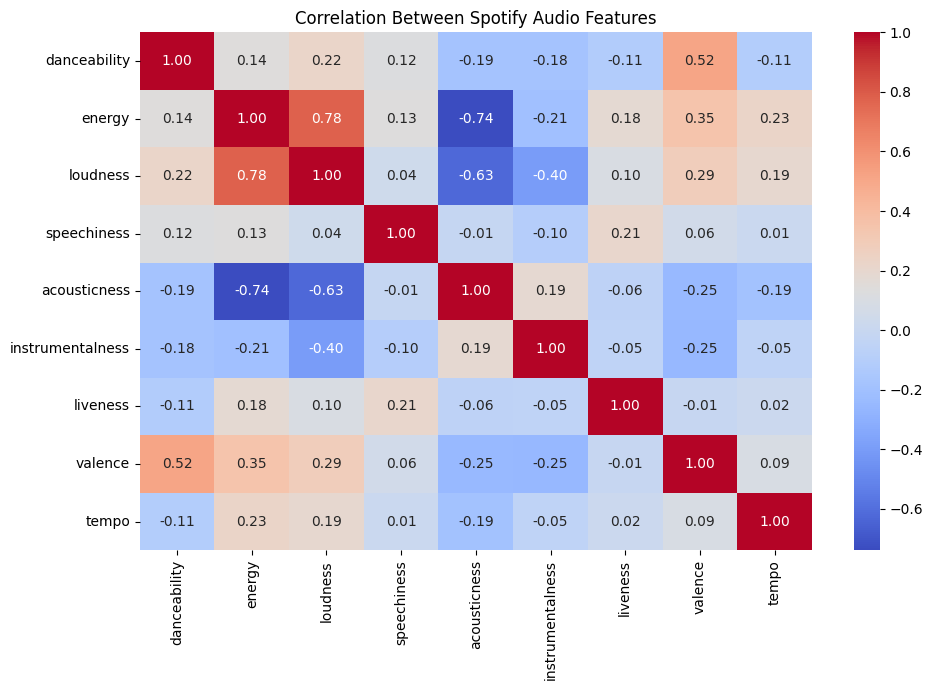

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Spotify Audio Features")
plt.tight_layout()
plt.show()

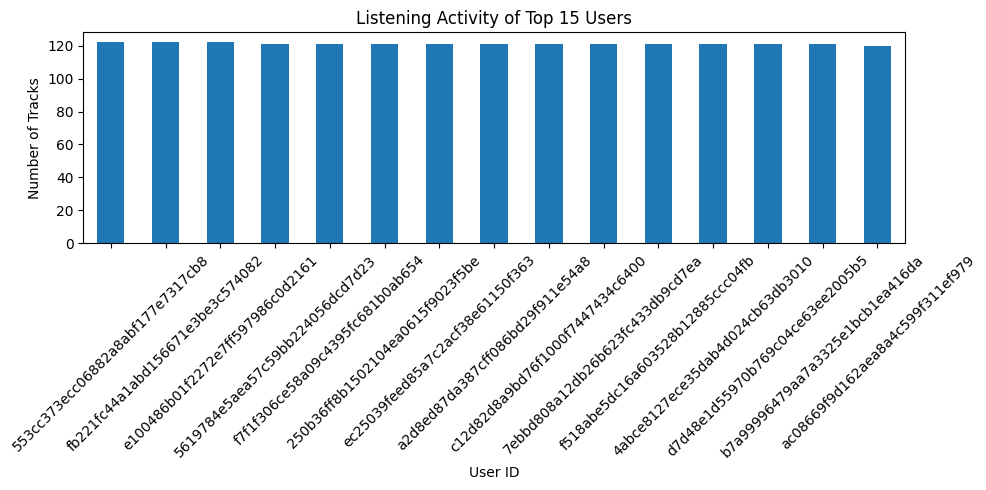

In [ ]:
user_counts = df['user_id'].value_counts().head(15)

plt.figure(figsize=(10, 5))

user_counts.plot(kind='bar')

plt.title("Listening Activity of Top 15 Users")
plt.xlabel("User ID")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

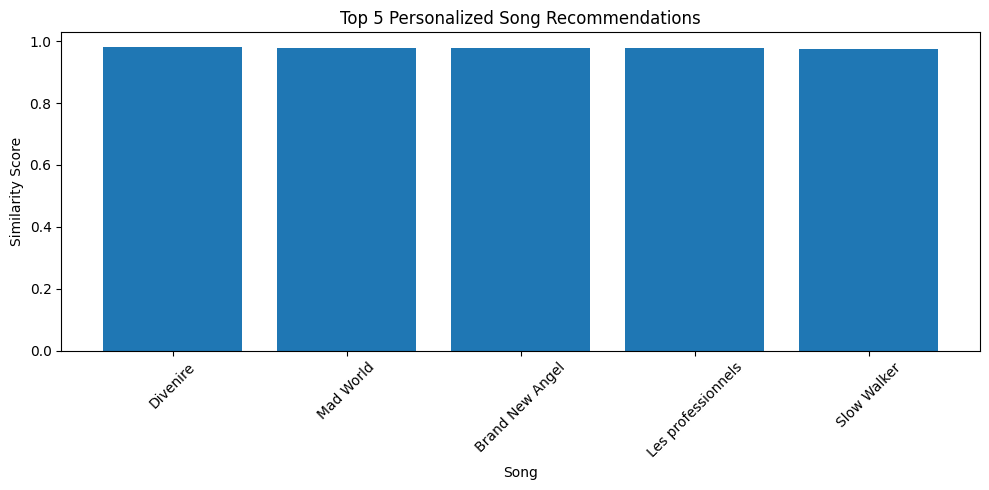

In [ ]:
top_5 = recommendations_clean.head(5).copy()

plt.figure(figsize=(10, 5))

plt.bar(
    top_5['trackname'].astype(str),
    top_5['recommendation_score']
)

plt.title("Top 5 Personalized Song Recommendations")
plt.xlabel("Song")
plt.ylabel("Similarity Score")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print("----- DATASET SUMMARY -----")

print("Total tracks:", df['trackname'].nunique())
print("Total artists:", df['artistname'].nunique())
print("Total playlists:", df['playlistname'].nunique())
print("Total users:", df['user_id'].nunique())

print("\n----- MODEL SUMMARY -----")

print("Number of features:", len(features))
print("Features:", features)

print("\n----- RECOMMENDATION RESULT -----")

print(top_5[
    ['trackname', 'artistname', 'recommendation_score']
].to_string(index=False))

----- DATASET SUMMARY -----
Total tracks: 21454
Total artists: 6185
Total playlists: 1078
Total users: 250

----- MODEL SUMMARY -----
Number of features: 9
Features: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

----- RECOMMENDATION RESULT -----
         trackname                    artistname  recommendation_score
          Divenire              Ludovico Einaudi              0.979681
         Mad World        Vitamin String Quartet              0.979645
   Brand New Angel                  Jeff Bridges              0.979492
Les professionnels                           Air              0.976630
       Slow Walker Béla Fleck and the Flecktones              0.975587
